
# PRDM9 background sampling — production notebook

This notebook rebuilds the PRDM9 background sampling step for publication use.

It produces two background datasets:

- **`datasetA_matched`**: exact **length distribution** matching plus **GC%** and **mononucleotide entropy** matching.
- **`datasetB_global`**: exact **length distribution** matching only, with **no GC% / entropy restriction**.

## What is intentionally improved relative to the exploratory notebook

The exploratory notebook had the right idea, but for a production dataset we want a tighter sampling design:

1. **Exact length matching**
   - The exploratory version drew from a *clipped* PRDM9 length distribution.
   - Here, both datasets match the **empirical PRDM9 length distribution exactly**.

2. **Exact uniform proposal sampling among non-PRDM9 starts**
   - For a requested window length `L`, start positions are proposed **uniformly across the non-PRDM9 genome**.
   - Windows are then screened by the same valid-base rule used for PRDM9.
   - This avoids bias from weighting gaps only by raw gap length, while keeping validity handling explicit and symmetric.

3. **Explicit valid-base filtering**
   - Both PRDM9 and background windows are filtered using `ValidFrac >= MIN_VALID_FRAC`.
   - Background draws are expanded until the requested number of valid windows is reached.
   - This avoids accidentally matching against windows spanning substantial `N` content.

4. **Fast, exact feature computation**
   - GC% and mononucleotide entropy are computed from **A/C/G/T prefix sums**, not by repeated sequence slicing.

5. **Publication-oriented validation**
   - The notebook saves clean validation figures, quantitative distance metrics, and a metadata JSON summarizing the run.

## Matching strategy

- **Length** is matched exactly by construction.
- **GC% and entropy** for `datasetA_matched` are matched using the exploratory notebook’s spirit:
  - PRDM9 windows are assigned to fixed-width GC and entropy bins.
  - Background candidates are sampled uniformly at the same exact length.
  - Selection is done in two passes:
    1. exact bin match where possible,
    2. nearest-neighbor fallback in GC/entropy space for any residual unmet demand.

This makes the method both faithful to the original strategy and more robust when bins are sparse.


In [7]:
!pip install pandas pyfaidx pyranges scipy rich matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.3/87.3 kB 36.7 MB/s eta 0:00:00


In [8]:

# Core setup
import os
import json
import math
import gc
from pathlib import Path
from functools import lru_cache
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import pyranges as pr
from pyfaidx import Fasta
from joblib import Parallel, delayed
from tqdm.auto import tqdm

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import ks_2samp, wasserstein_distance

from rich.console import Console
from rich.table import Table
from rich.panel import Panel

# ------------------------------------------------------------------
# Reproducibility and threading
# ------------------------------------------------------------------
RNG_SEED = 1337
GLOBAL_RNG = np.random.default_rng(RNG_SEED)

N_CORES = min(64, os.cpu_count() or 1)

for env_var in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[env_var] = str(N_CORES)

console = Console()

console.print(Panel.fit(
    f"[bold]PRDM9 sampling notebook[/bold]\n"
    f"Seed: {RNG_SEED}\n"
    f"CPU budget: {N_CORES}",
    title="Run configuration"
))

# ------------------------------------------------------------------
# User-tunable parameters
# ------------------------------------------------------------------
PRDM9_BED = "prdm9_peaks/HEK293_PRDM9-B_HA_MACS2_hg38.bed"
FASTA = "hg38.fa"
FAI = "hg38.fa.fai"

OUTDIR = Path("data_prdm9_sampling_production")
FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
METADIR = OUTDIR / "metadata"

for p in [OUTDIR, FIGDIR, TABDIR, METADIR]:
    p.mkdir(parents=True, exist_ok=True)

BACKGROUND_MULTIPLIER = 3

# fixed-width matching bins for datasetA
GC_BIN_WIDTH = 1.0          # percent GC
ENTROPY_BIN_WIDTH = 0.05    # bits (mono entropy)

# genome / validity choices
KEEP_CANONICAL_ONLY = True
MIN_VALID_FRAC = 1.00       # publication default: require fully A/C/G/T-covered windows

# candidate-pool controls for datasetA
POOL_FACTOR = 80
MIN_CANDIDATE_POOL = 2000
MAX_POOL_EXPANSIONS = 6
POOL_GROWTH = 2.0

# validation figures
SAVE_DPI = 300

# plotting palette
PALETTE = {
    "PRDM9": "#5B2A86",
    "datasetA_matched": "#1B9E77",
    "datasetB_global": "#D95F02",
}

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": SAVE_DPI,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

console.log(f"Outputs will be written to: {OUTDIR.resolve()}")


╭─── Run configuration ───╮
│ PRDM9 sampling notebook │
│ Seed: 1337              │
│ CPU budget: 64          │
╰─────────────────────────╯

[13:19:36] Outputs will be written to: /home/jovyan/prdm9_new/data_prdm9_sampling_production      ]8;id=7229272;file:///tmp/ipykernel_2000/3857661277.py\3857661277.py]8;;\:]8;id=7229273;file:///tmp/ipykernel_2000/3857661277.py#107\107]8;;\

In [18]:

# Helper functions: I/O, chromosome handling, fast interval statistics

def canonical_chromosomes():
    return [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

def read_fai_sizes(fai_path):
    rows = []
    with open(fai_path, "r") as f:
        for line in f:
            chrom, length = line.rstrip("\n").split("\t")[:2]
            rows.append((chrom, int(length)))
    return pd.DataFrame(rows, columns=["Chromosome", "Length"])

def read_bed3(path):
    df = pd.read_csv(
        path,
        sep="\t",
        header=None,
        comment="#",
        usecols=[0, 1, 2],
        names=["Chromosome", "Start", "End"],
    )
    df = df[df["End"] > df["Start"]].copy()
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    return df.reset_index(drop=True)

def interval_signature(df):
    return pd.Series(
        df["Chromosome"].astype(str) + ":" +
        df["Start"].astype(str) + "-" +
        df["End"].astype(str),
        index=df.index,
    )

def add_panel_label(ax, label):
    ax.text(
        -0.10, 1.05, label,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="bottom",
        ha="left",
    )

def summarize_series(x):
    x = np.asarray(x, dtype=float)
    return {
        "n": int(np.isfinite(x).sum()),
        "mean": float(np.nanmean(x)),
        "sd": float(np.nanstd(x, ddof=1)),
        "median": float(np.nanmedian(x)),
        "q25": float(np.nanquantile(x, 0.25)),
        "q75": float(np.nanquantile(x, 0.75)),
        "min": float(np.nanmin(x)),
        "max": float(np.nanmax(x)),
    }

def base_prefix_from_seq(seq):
    seq_bytes = np.frombuffer(seq.encode("ascii"), dtype=np.uint8)

    is_a = (seq_bytes == ord("A"))
    is_c = (seq_bytes == ord("C"))
    is_g = (seq_bytes == ord("G"))
    is_t = (seq_bytes == ord("T"))
    is_valid = is_a | is_c | is_g | is_t

    pref = {}
    for name, mask in [("A", is_a), ("C", is_c), ("G", is_g), ("T", is_t), ("valid", is_valid)]:
        arr = np.zeros(len(seq_bytes) + 1, dtype=np.int64)
        arr[1:] = np.cumsum(mask, dtype=np.int64)
        pref[name] = arr
    pref["length"] = len(seq_bytes)
    return pref

def build_prefixes(fasta_path, chroms):
    fa = Fasta(fasta_path, as_raw=True, sequence_always_upper=True)
    prefixes = {}
    for chrom in tqdm(chroms, desc="Building base prefix sums"):
        seq = fa[chrom][:]
        prefixes[chrom] = base_prefix_from_seq(seq)
    return prefixes

def _stats_one_chrom(sub, pref):
    idx = sub.index.to_numpy()
    s = sub["Start"].to_numpy(dtype=np.int64)
    e = sub["End"].to_numpy(dtype=np.int64)
    length = (e - s).astype(np.int64)

    a = pref["A"][e] - pref["A"][s]
    c = pref["C"][e] - pref["C"][s]
    g = pref["G"][e] - pref["G"][s]
    t = pref["T"][e] - pref["T"][s]
    valid = pref["valid"][e] - pref["valid"][s]

    out = pd.DataFrame(index=idx)
    out["Len"] = length
    out["A_count"] = a
    out["C_count"] = c
    out["G_count"] = g
    out["T_count"] = t
    out["ValidBases"] = valid
    out["ValidFrac"] = np.divide(valid, length, out=np.zeros_like(valid, dtype=float), where=(length > 0))
    out["GC_pct"] = np.divide(
        100.0 * (c + g),
        valid,
        out=np.full_like(valid, np.nan, dtype=float),
        where=(valid > 0),
    )

    counts = np.stack([a, c, g, t], axis=1).astype(float)
    p = np.divide(
        counts,
        valid[:, None],
        out=np.zeros_like(counts, dtype=float),
        where=(valid[:, None] > 0),
    )
    logp = np.zeros_like(p, dtype=float)
    mask = p > 0
    logp[mask] = np.log2(p[mask])
    entropy = -(p * logp).sum(axis=1)
    entropy[valid == 0] = np.nan
    out["Entropy"] = entropy
    return out

def compute_interval_stats(df, prefixes, n_jobs=N_CORES):
    if len(df) == 0:
        return df.copy()

    groups = []
    for chrom, sub in df.groupby("Chromosome", sort=False):
        if chrom not in prefixes:
            continue
        groups.append((chrom, sub))

    if len(groups) == 0:
        out = df.copy()
        out["Len"] = (out["End"] - out["Start"]).astype(np.int64)
        out["A_count"] = np.nan
        out["C_count"] = np.nan
        out["G_count"] = np.nan
        out["T_count"] = np.nan
        out["ValidBases"] = np.nan
        out["ValidFrac"] = np.nan
        out["GC_pct"] = np.nan
        out["Entropy"] = np.nan
        return out

    parts = Parallel(
        n_jobs=min(n_jobs, len(groups)),
        prefer="threads",
        verbose=10,
    )(
        delayed(_stats_one_chrom)(sub, prefixes[chrom]) for chrom, sub in groups
    )

    stats = pd.concat(parts, axis=0).sort_index()
    out = df.copy()
    for col in stats.columns:
        out[col] = stats[col]
    return out

def assert_no_prdm9_overlap(bg_df, prdm9_union_df):
    if len(bg_df) == 0:
        return
    bg_gr = pr.PyRanges(bg_df[["Chromosome", "Start", "End"]])
    prdm9_gr = pr.PyRanges(prdm9_union_df[["Chromosome", "Start", "End"]])
    ov = bg_gr.join(prdm9_gr)
    n_ov = 0 if ov.df is None else len(ov.df)
    assert n_ov == 0, f"Background overlaps PRDM9 union: {n_ov} overlaps found"

def count_self_overlaps(df):
    if len(df) <= 1:
        return 0
    gr = pr.PyRanges(df[["Chromosome", "Start", "End"]].copy())
    ov = gr.join(gr)
    ov_df = ov.df
    #print(ov_df.columns)
    if ov_df is None or len(ov_df) == 0:
        return 0
    # ignore exact self rows
    same = (
        (ov_df["Start"] == ov_df["Start_b"]) &
        (ov_df["End"] == ov_df["End_b"]) #&
     #   (ov_df["Chromosome"] == ov_df["Chromosome_b"])
    )
    ov_df = ov_df.loc[~same]
    if len(ov_df) == 0:
        return 0
    # each pair counted twice
    return int(len(ov_df) // 2)

def gc_bin(x):
    return np.floor(np.asarray(x, dtype=float) / GC_BIN_WIDTH).astype(int)

def entropy_bin(x):
    return np.floor(np.asarray(x, dtype=float) / ENTROPY_BIN_WIDTH).astype(int)

def robust_scale(x):
    x = np.asarray(x, dtype=float)
    q25, q75 = np.nanquantile(x, [0.25, 0.75])
    iqr = q75 - q25
    return float(iqr if iqr > 0 else np.nanstd(x, ddof=1) if np.nanstd(x, ddof=1) > 0 else 1.0)


In [10]:

# Load PRDM9 peaks and genome sizes

sizes = read_fai_sizes(FAI)
fai_chroms = set(sizes["Chromosome"])

prdm9_raw = read_bed3(PRDM9_BED)
prdm9_raw["Len"] = (prdm9_raw["End"] - prdm9_raw["Start"]).astype(np.int64)

if KEEP_CANONICAL_ONLY:
    keep = set(canonical_chromosomes())
    prdm9_raw = prdm9_raw[prdm9_raw["Chromosome"].isin(keep)].reset_index(drop=True)
    sizes = sizes[sizes["Chromosome"].isin(keep)].reset_index(drop=True)

prdm9_raw = prdm9_raw[prdm9_raw["Chromosome"].isin(fai_chroms)].reset_index(drop=True)

chroms = [c for c in sizes["Chromosome"].tolist() if c in set(prdm9_raw["Chromosome"])]

console.log(f"Usable chromosomes: {len(chroms)}")
console.log(f"Raw PRDM9 intervals: {len(prdm9_raw):,}")

prefixes = build_prefixes(FASTA, chroms)
prdm9 = compute_interval_stats(prdm9_raw, prefixes, n_jobs=N_CORES)

n_before_valid = len(prdm9)
prdm9 = prdm9[np.isfinite(prdm9["GC_pct"]) & np.isfinite(prdm9["Entropy"])].copy()
prdm9 = prdm9[prdm9["ValidFrac"] >= MIN_VALID_FRAC].copy()
prdm9 = prdm9.reset_index(drop=True)

console.log(f"Retained PRDM9 intervals after validity filtering: {len(prdm9):,} / {n_before_valid:,}")

prdm9["GC_bin"] = gc_bin(prdm9["GC_pct"])
prdm9["Ent_bin"] = entropy_bin(prdm9["Entropy"])
prdm9["Class"] = "PRDM9"

prdm9_bed_path = OUTDIR / "prdm9_filtered.bed"
prdm9_stats_path = TABDIR / "prdm9_filtered.stats.tsv"

prdm9[["Chromosome", "Start", "End"]].to_csv(prdm9_bed_path, sep="\t", header=False, index=False)
prdm9.to_csv(prdm9_stats_path, sep="\t", index=False)

display(prdm9.head())

summary_table = Table(title="PRDM9 summary after filtering")
for col in ["Metric", "Value"]:
    summary_table.add_column(col)
summary_table.add_row("Intervals", f"{len(prdm9):,}")
summary_table.add_row("Median length (bp)", f"{prdm9['Len'].median():.1f}")
summary_table.add_row("Median GC (%)", f"{prdm9['GC_pct'].median():.2f}")
summary_table.add_row("Median entropy (bits)", f"{prdm9['Entropy'].median():.3f}")
summary_table.add_row("Min valid fraction", f"{prdm9['ValidFrac'].min():.3f}")
console.print(summary_table)


[13:19:37] Usable chromosomes: 24                                                                  ]8;id=7229280;file:///tmp/ipykernel_2000/2172122755.py\2172122755.py]8;;\:]8;id=7229281;file:///tmp/ipykernel_2000/2172122755.py#18\18]8;;\

           Raw PRDM9 intervals: 60,589                                                             ]8;id=7229287;file:///tmp/ipykernel_2000/2172122755.py\2172122755.py]8;;\:]8;id=7229288;file:///tmp/ipykernel_2000/2172122755.py#19\19]8;;\

Building base prefix sums:   0%|          | 0/24 [00:00<?, ?it/s]

[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=24)]: Done   4 out of  24 | elapsed:    0.0s remaining:    0.2s
[Parallel(n_jobs=24)]: Done   7 out of  24 | elapsed:    0.0s remaining:    0.1s
[Parallel(n_jobs=24)]: Done  10 out of  24 | elapsed:    0.1s remaining:    0.1s
[Parallel(n_jobs=24)]: Done  13 out of  24 | elapsed:    0.1s remaining:    0.1s
[Parallel(n_jobs=24)]: Done  16 out of  24 | elapsed:    0.2s remaining:    0.1s
[Parallel(n_jobs=24)]: Done  19 out of  24 | elapsed:    0.2s remaining:    0.1s
[Parallel(n_jobs=24)]: Done  22 out of  24 | elapsed:    0.2s remaining:    0.0s
[Parallel(n_jobs=24)]: Done  24 out of  24 | elapsed:    0.2s finished


[13:25:42] Retained PRDM9 intervals after validity filtering: 60,580 / 60,589                      ]8;id=7229294;file:///tmp/ipykernel_2000/2172122755.py\2172122755.py]8;;\:]8;id=7229295;file:///tmp/ipykernel_2000/2172122755.py#29\29]8;;\

,Chromosome,Start,End,Len,A_count,C_count,G_count,T_count,ValidBases,ValidFrac,GC_pct,Entropy,GC_bin,Ent_bin,Class
0,chr1,15638,17806,2168,438,626,668,436,2168,1.0,59.686347,1.972301,59,39,PRDM9
1,chr1,29251,29752,501,51,239,132,79,501,1.0,74.051896,1.772141,74,35,PRDM9
2,chr1,34779,35008,229,58,52,75,44,229,1.0,55.458515,1.972120,55,39,PRDM9
3,chr1,35827,36151,324,64,104,96,60,324,1.0,61.728395,1.958938,61,39,PRDM9
4,chr1,133287,133519,232,33,81,72,46,232,1.0,65.948276,1.916984,65,38,PRDM9


  PRDM9 summary after filtering   
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ Metric                ┃ Value  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ Intervals             │ 60,580 │
│ Median length (bp)    │ 717.0  │
│ Median GC (%)         │ 58.31  │
│ Median entropy (bits) │ 1.958  │
│ Min valid fraction    │ 1.000  │
└───────────────────────┴────────┘

In [11]:

# Build the non-PRDM9 genomic universe

chrom_len = dict(zip(sizes["Chromosome"], sizes["Length"]))

genome_ranges = pr.PyRanges(pd.DataFrame({
    "Chromosome": chroms,
    "Start": np.zeros(len(chroms), dtype=np.int64),
    "End": np.array([chrom_len[c] for c in chroms], dtype=np.int64),
}))

# exclude union of PRDM9 peaks, not raw rows
prdm9_union = pr.PyRanges(prdm9[["Chromosome", "Start", "End"]]).merge()
prdm9_union_df = prdm9_union.df.sort_values(["Chromosome", "Start", "End"]).reset_index(drop=True)

complement = genome_ranges.subtract(prdm9_union)
universe = complement.df.sort_values(["Chromosome", "Start", "End"]).reset_index(drop=True)
universe["GapLen"] = (universe["End"] - universe["Start"]).astype(np.int64)

console.log(f"Complement intervals (genomic gaps outside PRDM9 union): {len(universe):,}")
console.log(f"Total complement bp: {int(universe['GapLen'].sum()):,}")

gap_by_chrom = {}
for chrom, sub in universe.groupby("Chromosome", sort=False):
    gap_by_chrom[chrom] = {
        "Start": sub["Start"].to_numpy(dtype=np.int64),
        "End": sub["End"].to_numpy(dtype=np.int64),
        "GapLen": sub["GapLen"].to_numpy(dtype=np.int64),
    }

display(universe.head())


[13:25:43] Complement intervals (genomic gaps outside PRDM9 union): 60,604                          ]8;id=7229302;file:///tmp/ipykernel_2000/611875254.py\611875254.py]8;;\:]8;id=7229303;file:///tmp/ipykernel_2000/611875254.py#19\19]8;;\

           Total complement bp: 3,018,454,737                                                       ]8;id=7229309;file:///tmp/ipykernel_2000/611875254.py\611875254.py]8;;\:]8;id=7229310;file:///tmp/ipykernel_2000/611875254.py#20\20]8;;\

/tmp/ipykernel_2000/611875254.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, sub in universe.groupby("Chromosome", sort=False):


,Chromosome,Start,End,GapLen
0,chr1,0,15638,15638
1,chr1,17806,29251,11445
2,chr1,29752,34779,5027
3,chr1,35008,35827,819
4,chr1,36151,133287,97136


In [12]:

# Exact uniform start samplers conditioned on requested length

@lru_cache(maxsize=None)
def eligible_gap_arrays(length_bp):
    chrom_list = []
    gap_start = []
    gap_end = []
    eligible = []

    for chrom, arrs in gap_by_chrom.items():
        e = arrs["GapLen"] - int(length_bp) + 1
        mask = e > 0
        if not np.any(mask):
            continue
        chrom_arr = np.array([chrom] * int(mask.sum()), dtype=object)
        chrom_list.append(chrom_arr)
        gap_start.append(arrs["Start"][mask])
        gap_end.append(arrs["End"][mask])
        eligible.append(e[mask].astype(np.int64))

    if len(eligible) == 0:
        return {
            "Chromosome": np.array([], dtype=object),
            "GapStart": np.array([], dtype=np.int64),
            "GapEnd": np.array([], dtype=np.int64),
            "EligibleStarts": np.array([], dtype=np.int64),
            "CumEligible": np.array([], dtype=np.int64),
            "TotalEligible": 0,
        }

    chrom_vec = np.concatenate(chrom_list)
    start_vec = np.concatenate(gap_start).astype(np.int64)
    end_vec = np.concatenate(gap_end).astype(np.int64)
    elig_vec = np.concatenate(eligible).astype(np.int64)
    cum = np.cumsum(elig_vec, dtype=np.int64)
    total = int(cum[-1])

    return {
        "Chromosome": chrom_vec,
        "GapStart": start_vec,
        "GapEnd": end_vec,
        "EligibleStarts": elig_vec,
        "CumEligible": cum,
        "TotalEligible": total,
    }

def sample_unique_offsets(total, n, rng):
    if n > total:
        raise ValueError(f"Requested {n} starts, but only {total} eligible starts exist")
    offs = rng.choice(total, size=n, replace=False)
    offs = np.asarray(offs, dtype=np.int64)
    offs.sort()
    return offs

def sample_uniform_windows_of_length(length_bp, n, seed):
    arrs = eligible_gap_arrays(int(length_bp))
    total = arrs["TotalEligible"]
    if total == 0:
        raise ValueError(f"No eligible starts available for length {length_bp}")
    if n > total:
        raise ValueError(f"Requested {n} windows of length {length_bp}, but only {total} eligible starts exist")

    rng = np.random.default_rng(seed)
    offsets = sample_unique_offsets(total, n, rng)

    gap_idx = np.searchsorted(arrs["CumEligible"], offsets, side="right")
    prev_cum = np.where(gap_idx == 0, 0, arrs["CumEligible"][gap_idx - 1])
    start = arrs["GapStart"][gap_idx] + (offsets - prev_cum)
    end = start + int(length_bp)

    out = pd.DataFrame({
        "Chromosome": arrs["Chromosome"][gap_idx],
        "Start": start.astype(np.int64),
        "End": end.astype(np.int64),
    })
    return out



def sample_valid_uniform_windows_of_length(length_bp, n, seed, min_valid_frac=MIN_VALID_FRAC):
    """
    Rejection-sampling wrapper:
    propose starts uniformly from the non-PRDM9 complement,
    compute validity/GC/entropy,
    keep unique windows passing the validity threshold,
    and expand until n accepted windows are obtained.
    """
    arrs = eligible_gap_arrays(int(length_bp))
    total = int(arrs["TotalEligible"])
    if total == 0:
        raise ValueError(f"No eligible starts available for length {length_bp}")

    rng = np.random.default_rng(seed)
    accepted_parts = []
    seen = set()

    pool_n = min(total, max(int(n), int(math.ceil(1.5 * n))))
    rounds = 0

    while sum(len(x) for x in accepted_parts) < n and rounds < MAX_POOL_EXPANSIONS + 4:
        draw_seed = int(rng.integers(0, 2**32 - 1))
        sampled = sample_uniform_windows_of_length(int(length_bp), pool_n, seed=draw_seed)
        sampled = compute_interval_stats(sampled, prefixes, n_jobs=min(N_CORES, 8))
        sampled = sampled[np.isfinite(sampled["GC_pct"]) & np.isfinite(sampled["Entropy"])].copy()
        sampled = sampled[sampled["ValidFrac"] >= min_valid_frac].copy()

        if len(sampled):
            sampled["sig"] = interval_signature(sampled)
            sampled = sampled.loc[~sampled["sig"].isin(seen)].copy()
            for s in sampled["sig"]:
                seen.add(s)
            sampled = sampled.drop(columns="sig")
            accepted_parts.append(sampled)

        if sum(len(x) for x in accepted_parts) >= n:
            break

        if pool_n >= total:
            # proposal pool already spans the full non-PRDM9 universe for this length
            break

        pool_n = min(total, int(math.ceil(pool_n * POOL_GROWTH)))
        rounds += 1

    if not accepted_parts:
        raise RuntimeError(f"Length {length_bp}: no valid windows could be sampled")

    out = pd.concat(accepted_parts, ignore_index=True)
    out = out.drop_duplicates(["Chromosome", "Start", "End"]).reset_index(drop=True)

    if len(out) < n:
        raise RuntimeError(
            f"Length {length_bp}: only {len(out)} valid unique windows obtained, need {n}"
        )

    return out.iloc[:n].copy().reset_index(drop=True)

def seed_stream(base_seed, *parts):
    ss = np.random.SeedSequence([base_seed, *[abs(hash(x)) % (2**32) for x in parts]])
    return int(ss.generate_state(1)[0])

# warm cache for observed PRDM9 lengths
observed_lengths = sorted(prdm9["Len"].unique().tolist())
_ = [eligible_gap_arrays(int(L)) for L in tqdm(observed_lengths, desc="Preparing eligible length caches")]

length_counts = (
    prdm9["Len"]
    .value_counts()
    .sort_index()
    .rename_axis("Len")
    .reset_index(name="PRDM9_n")
)
length_counts["dataset_n"] = length_counts["PRDM9_n"] * BACKGROUND_MULTIPLIER
display(length_counts.head())


Preparing eligible length caches:   0%|          | 0/5409 [00:00<?, ?it/s]

,Len,PRDM9_n,dataset_n
0,195,148,444
1,196,164,492
2,197,143,429
3,198,125,375
4,199,124,372


In [13]:

# datasetB_global: exact length-matched only

def sample_length_only_group(length_bp, n_prdm9, multiplier, base_seed):
    n_needed = int(n_prdm9) * int(multiplier)
    seed = seed_stream(base_seed, "datasetB_global", int(length_bp), int(n_prdm9))
    sub = sample_valid_uniform_windows_of_length(int(length_bp), n_needed, seed=seed, min_valid_frac=MIN_VALID_FRAC)
    return sub

datasetB_parts = Parallel(
    n_jobs=min(N_CORES, len(length_counts)),
    prefer="threads",
    verbose=10,
)(
    delayed(sample_length_only_group)(row.Len, row.PRDM9_n, BACKGROUND_MULTIPLIER, RNG_SEED + 1000)
    for row in tqdm(length_counts.itertuples(index=False), total=len(length_counts), desc="datasetB length groups")
)

datasetB = pd.concat(datasetB_parts, ignore_index=True).reset_index(drop=True)
datasetB["GC_bin"] = gc_bin(datasetB["GC_pct"])
datasetB["Ent_bin"] = entropy_bin(datasetB["Entropy"])
datasetB["Class"] = "datasetB_global"

expected_B = int(len(prdm9) * BACKGROUND_MULTIPLIER)
assert len(datasetB) == expected_B, f"datasetB_global count mismatch: {len(datasetB)} vs expected {expected_B}"
assert_no_prdm9_overlap(datasetB, prdm9_union_df)

datasetB_bed_path = OUTDIR / "datasetB_global.length_only.bed"
datasetB_stats_path = TABDIR / "datasetB_global.length_only.stats.tsv"

datasetB[["Chromosome", "Start", "End"]].to_csv(datasetB_bed_path, sep="\t", header=False, index=False)
datasetB.to_csv(datasetB_stats_path, sep="\t", index=False)

console.log(f"datasetB_global intervals: {len(datasetB):,}")
display(datasetB.head())


datasetB length groups:   0%|          | 0/5409 [00:00<?, ?it/s]

[Parallel(n_jobs=64)]: Using backend ThreadingBackend with 64 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend Th

[13:29:59] datasetB_global intervals: 181,740                                                      ]8;id=7229317;file:///tmp/ipykernel_2000/2473346200.py\2473346200.py]8;;\:]8;id=7229318;file:///tmp/ipykernel_2000/2473346200.py#33\33]8;;\

,Chromosome,Start,End,Len,A_count,C_count,G_count,T_count,ValidBases,ValidFrac,GC_pct,Entropy,GC_bin,Ent_bin,Class
0,chr1,3022814,3023009,195,33,57,56,49,195,1.0,57.948718,1.970036,57,39,datasetB_global
1,chr1,8662350,8662545,195,72,43,37,43,195,1.0,41.025641,1.947622,41,38,datasetB_global
2,chr1,15650782,15650977,195,47,43,36,69,195,1.0,40.512821,1.956045,40,39,datasetB_global
3,chr1,18857685,18857880,195,55,63,33,44,195,1.0,49.230769,1.960031,49,39,datasetB_global
4,chr1,25151438,25151633,195,77,39,46,33,195,1.0,43.589744,1.919012,43,38,datasetB_global


In [14]:

# datasetA_matched: exact length + GC% / entropy matching

GLOBAL_GC_SCALE = robust_scale(prdm9["GC_pct"])
GLOBAL_ENT_SCALE = robust_scale(prdm9["Entropy"])

def select_candidates_bin_first_then_nearest(candidates, target_sub, multiplier):
    targets_expanded = target_sub.loc[target_sub.index.repeat(multiplier)].copy().reset_index(drop=True)
    targets_expanded["slot_id"] = np.arange(len(targets_expanded), dtype=np.int64)

    cand = candidates.copy().reset_index(drop=True)
    cand["candidate_id"] = np.arange(len(cand), dtype=np.int64)

    selected_candidate_ids = []
    matched_slot_ids = []

    # pass 1: exact GC/entropy bin matching
    target_bin_groups = (
        targets_expanded
        .groupby(["GC_bin", "Ent_bin"], sort=False)
        .groups
    )

    for bin_key, target_idx in sorted(target_bin_groups.items(), key=lambda kv: len(kv[1]), reverse=True):
        gc_b, ent_b = bin_key
        cand_idx = cand.index[(cand["GC_bin"] == gc_b) & (cand["Ent_bin"] == ent_b)].tolist()
        take = min(len(target_idx), len(cand_idx))
        if take > 0:
            selected_candidate_ids.extend(cand.loc[cand_idx[:take], "candidate_id"].tolist())
            matched_slot_ids.extend(targets_expanded.loc[list(target_idx)[:take], "slot_id"].tolist())
            cand = cand.drop(index=cand_idx[:take]).reset_index(drop=True)

    remaining_targets = targets_expanded.loc[~targets_expanded["slot_id"].isin(matched_slot_ids)].copy()
    fallback_used = 0

    # pass 2: nearest-neighbor fallback in raw GC/entropy space
    if len(remaining_targets) > 0:
        cand_gc = cand["GC_pct"].to_numpy(dtype=float)
        cand_ent = cand["Entropy"].to_numpy(dtype=float)

        for _, tr in remaining_targets.iterrows():
            if len(cand) == 0:
                break
            d = ((cand_gc - float(tr["GC_pct"])) / GLOBAL_GC_SCALE) ** 2 + \
                ((cand_ent - float(tr["Entropy"])) / GLOBAL_ENT_SCALE) ** 2
            j = int(np.argmin(d))
            selected_candidate_ids.append(int(cand.iloc[j]["candidate_id"]))
            fallback_used += 1

            keep = np.ones(len(cand), dtype=bool)
            keep[j] = False
            cand = cand.loc[keep].reset_index(drop=True)
            cand_gc = cand["GC_pct"].to_numpy(dtype=float)
            cand_ent = cand["Entropy"].to_numpy(dtype=float)

    selected = candidates.loc[candidates["candidate_id"].isin(selected_candidate_ids)].copy().reset_index(drop=True)

    return selected, {
        "n_required": int(len(targets_expanded)),
        "n_selected": int(len(selected)),
        "fallback_used": int(fallback_used),
        "fallback_frac": float(fallback_used / len(targets_expanded)) if len(targets_expanded) else 0.0,
    }

def sample_matched_length_group(length_bp, target_sub, multiplier, base_seed):
    n_needed = int(len(target_sub) * multiplier)
    arrs = eligible_gap_arrays(int(length_bp))
    total_eligible = int(arrs["TotalEligible"])
    if total_eligible < n_needed:
        raise ValueError(
            f"Length {length_bp}: need {n_needed} windows but only {total_eligible} eligible starts exist"
        )

    pool_n = min(total_eligible, max(MIN_CANDIDATE_POOL, int(POOL_FACTOR * n_needed)))
    all_candidates = []
    seen = set()
    expansion = 0

    while expansion < MAX_POOL_EXPANSIONS:
        seed = seed_stream(base_seed, "datasetA_matched", int(length_bp), int(expansion), n_needed)
        sampled = sample_uniform_windows_of_length(int(length_bp), pool_n, seed=seed)
        sampled = compute_interval_stats(sampled, prefixes, n_jobs=min(N_CORES, 8))
        sampled = sampled[np.isfinite(sampled["GC_pct"]) & np.isfinite(sampled["Entropy"])].copy()
        sampled = sampled[sampled["ValidFrac"] >= MIN_VALID_FRAC].copy()

        if len(sampled):
            sampled["sig"] = interval_signature(sampled)
            sampled = sampled.loc[~sampled["sig"].isin(seen)].copy()
            for s in sampled["sig"]:
                seen.add(s)
            sampled = sampled.drop(columns="sig")
            sampled["GC_bin"] = gc_bin(sampled["GC_pct"])
            sampled["Ent_bin"] = entropy_bin(sampled["Entropy"])
            all_candidates.append(sampled)

        candidates = pd.concat(all_candidates, ignore_index=True) if all_candidates else pd.DataFrame()
        if len(candidates) >= n_needed:
            candidates = candidates.drop_duplicates(["Chromosome", "Start", "End"]).reset_index(drop=True)
            candidates["candidate_id"] = np.arange(len(candidates), dtype=np.int64)
            selected, meta = select_candidates_bin_first_then_nearest(candidates, target_sub, multiplier)
            if len(selected) == n_needed:
                meta["pool_size"] = int(len(candidates))
                meta["expansions"] = int(expansion + 1)
                meta["length_bp"] = int(length_bp)
                meta["target_n"] = int(len(target_sub))
                return selected, meta

        if pool_n >= total_eligible:
            break

        pool_n = min(total_eligible, int(math.ceil(pool_n * POOL_GROWTH)))
        expansion += 1

    raise RuntimeError(
        f"Length {length_bp}: could not sample a sufficient matched pool after {MAX_POOL_EXPANSIONS} expansions"
    )

targets_by_length = [sub.copy() for _, sub in prdm9.groupby("Len", sort=True)]

datasetA_results = Parallel(
    n_jobs=min(N_CORES, len(targets_by_length)),
    prefer="threads",
    verbose=10,
)(
    delayed(sample_matched_length_group)(
        int(sub["Len"].iloc[0]),
        sub,
        BACKGROUND_MULTIPLIER,
        RNG_SEED + 2000,
    )
    for sub in tqdm(targets_by_length, total=len(targets_by_length), desc="datasetA length groups")
)

datasetA_parts = [x[0] for x in datasetA_results]
datasetA_meta = pd.DataFrame([x[1] for x in datasetA_results]).sort_values("length_bp").reset_index(drop=True)

datasetA = pd.concat(datasetA_parts, ignore_index=True)
datasetA["Class"] = "datasetA_matched"

expected_A = int(len(prdm9) * BACKGROUND_MULTIPLIER)
assert len(datasetA) == expected_A, f"datasetA_matched count mismatch: {len(datasetA)} vs expected {expected_A}"
assert_no_prdm9_overlap(datasetA, prdm9_union_df)

datasetA_bed_path = OUTDIR / "datasetA_matched.len_gc_entropy.bed"
datasetA_stats_path = TABDIR / "datasetA_matched.len_gc_entropy.stats.tsv"
datasetA_meta_path = TABDIR / "datasetA_matched.length_group_metadata.tsv"

datasetA[["Chromosome", "Start", "End"]].to_csv(datasetA_bed_path, sep="\t", header=False, index=False)
datasetA.to_csv(datasetA_stats_path, sep="\t", index=False)
datasetA_meta.to_csv(datasetA_meta_path, sep="\t", index=False)

console.log(f"datasetA_matched intervals: {len(datasetA):,}")
console.log(f"datasetA fallback fraction (overall): {datasetA_meta['fallback_used'].sum() / datasetA_meta['n_required'].sum():.4f}")

display(datasetA_meta.head())
display(datasetA.head())


datasetA length groups:   0%|          | 0/5409 [00:00<?, ?it/s]

[Parallel(n_jobs=64)]: Using backend ThreadingBackend with 64 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Using backend Th

In [19]:

# Hard validation checks

def length_distribution_counts(df):
    return df["Len"].value_counts().sort_index()

prdm9_len_counts = length_distribution_counts(prdm9)
datasetA_len_counts = length_distribution_counts(datasetA)
datasetB_len_counts = length_distribution_counts(datasetB)

assert datasetA_len_counts.equals(prdm9_len_counts * BACKGROUND_MULTIPLIER), "datasetA exact length distribution mismatch"
assert datasetB_len_counts.equals(prdm9_len_counts * BACKGROUND_MULTIPLIER), "datasetB exact length distribution mismatch"

qc_rows = []

for name, df in [("datasetA_matched", datasetA), ("datasetB_global", datasetB)]:
    qc_rows.append({
        "Dataset": name,
        "Intervals": int(len(df)),
        "ExactDuplicates": int(df.duplicated(["Chromosome", "Start", "End"]).sum()),
        "SelfOverlaps": int(count_self_overlaps(df)),
        "MinValidFrac": float(df["ValidFrac"].min()),
        "MedianLen": float(df["Len"].median()),
        "MedianGC": float(df["GC_pct"].median()),
        "MedianEntropy": float(df["Entropy"].median()),
    })

qc_df = pd.DataFrame(qc_rows)
qc_df.to_csv(TABDIR / "background_qc_summary.tsv", sep="\t", index=False)
display(qc_df)

console.print(Panel.fit("[bold green]Core assertions passed[/bold green]\n"
                        "- exact length distribution matched in both datasets\n"
                        "- no PRDM9 overlap\n"
                        "- validity filter respected"))


,Dataset,Intervals,ExactDuplicates,SelfOverlaps,MinValidFrac,MedianLen,MedianGC,MedianEntropy
0,datasetA_matched,181740,0,328720,1.0,717.0,57.613169,1.963763
1,datasetB_global,181740,0,18003,1.0,717.0,39.658444,1.955415


╭──────────────────────────────────────────────────────╮
│ Core assertions passed                               │
│ - exact length distribution matched in both datasets │
│ - no PRDM9 overlap                                   │
│ - validity filter respected                          │
╰──────────────────────────────────────────────────────╯

In [20]:

# Quantitative validation metrics

def standardized_mean_difference(ref, other):
    ref = np.asarray(ref, dtype=float)
    other = np.asarray(other, dtype=float)
    v = (np.nanvar(ref, ddof=1) + np.nanvar(other, ddof=1)) / 2.0
    if not np.isfinite(v) or v <= 0:
        return 0.0
    return float((np.nanmean(other) - np.nanmean(ref)) / np.sqrt(v))

def compare_feature(ref, other, feature_name):
    ref_x = np.asarray(ref[feature_name], dtype=float)
    oth_x = np.asarray(other[feature_name], dtype=float)
    return {
        "Feature": feature_name,
        "KS_stat": float(ks_2samp(ref_x, oth_x).statistic),
        "Wasserstein": float(wasserstein_distance(ref_x, oth_x)),
        "SMD": float(standardized_mean_difference(ref_x, oth_x)),
        "Ref_mean": float(np.mean(ref_x)),
        "Other_mean": float(np.mean(oth_x)),
        "Ref_median": float(np.median(ref_x)),
        "Other_median": float(np.median(oth_x)),
    }

metric_rows = []
for dataset_name, df in [("datasetA_matched", datasetA), ("datasetB_global", datasetB)]:
    for feat in ["Len", "GC_pct", "Entropy"]:
        row = compare_feature(prdm9, df, feat)
        row["Dataset"] = dataset_name
        metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)
metrics_df = metrics_df[["Dataset", "Feature", "KS_stat", "Wasserstein", "SMD",
                         "Ref_mean", "Other_mean", "Ref_median", "Other_median"]]
metrics_df.to_csv(TABDIR / "sampling_validation_metrics.tsv", sep="\t", index=False)
display(metrics_df)


,Dataset,Feature,KS_stat,Wasserstein,SMD,Ref_mean,Other_mean,Ref_median,Other_median
0,datasetA_matched,Len,0.000000,0.000000,0.000000,1152.444619,1152.444619,717.000000,717.000000
1,datasetA_matched,GC_pct,0.066700,1.174405,-0.160073,58.570115,57.396591,58.310627,57.613169
2,datasetA_matched,Entropy,0.065374,0.009714,0.108999,1.929990,1.939703,1.957532,1.963763
3,datasetB_global,Len,0.000000,0.000000,0.000000,1152.444619,1152.444619,717.000000,717.000000
4,datasetB_global,GC_pct,0.791345,18.140767,-2.474310,58.570115,40.429354,58.310627,39.658444
5,datasetB_global,Entropy,0.055629,0.014638,0.173897,1.929990,1.943058,1.957532,1.955415


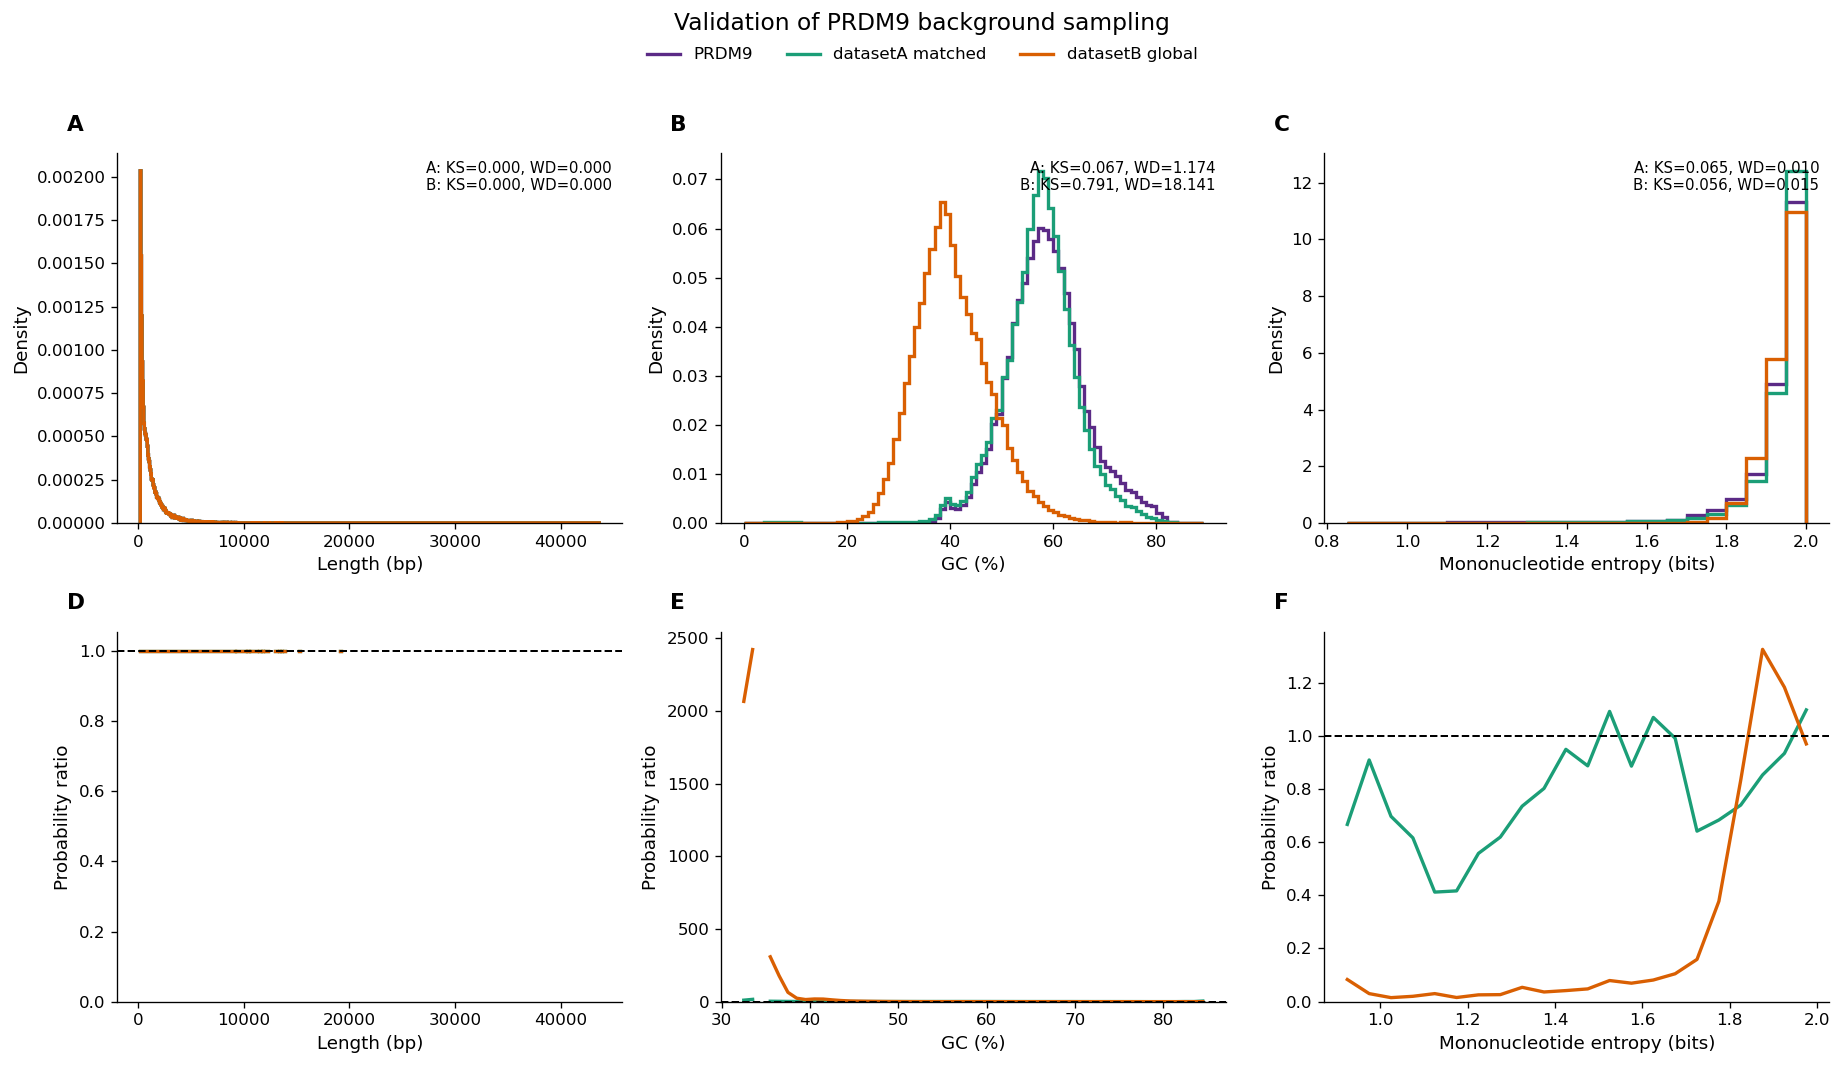

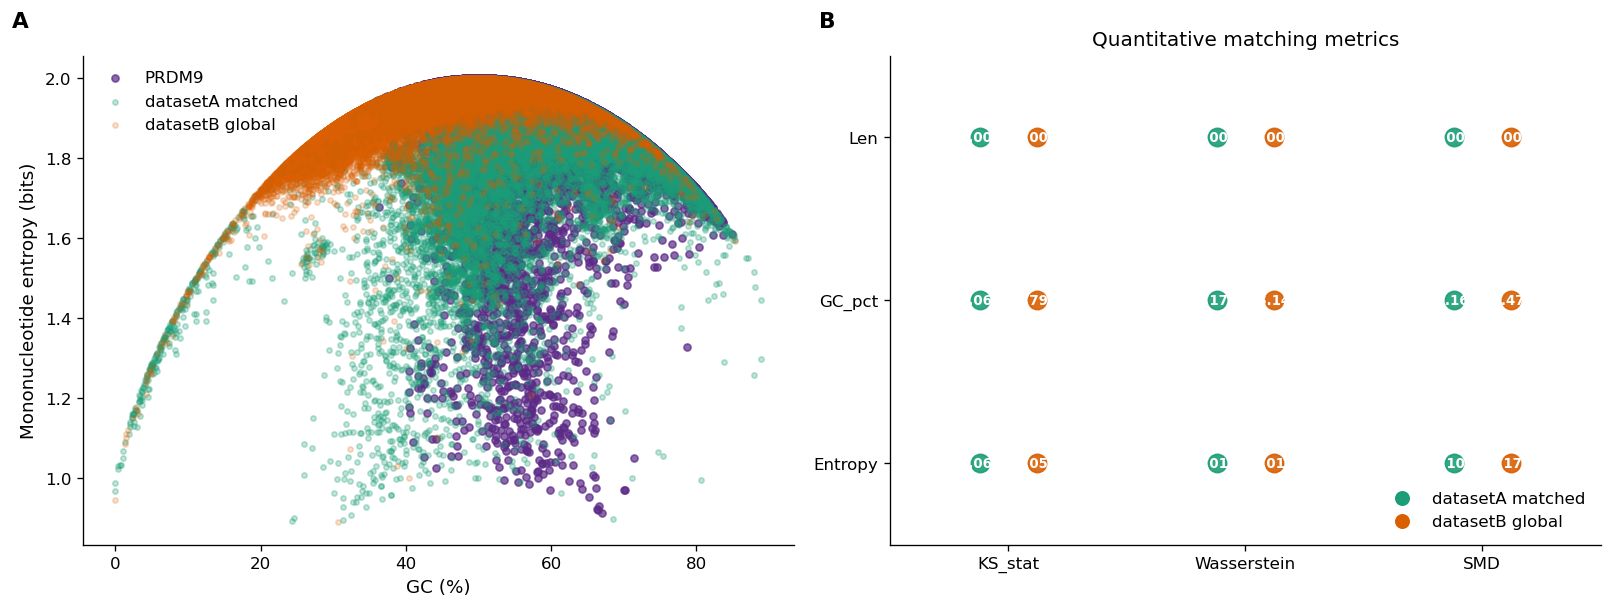

[14:18:09] Saved: data_prdm9_sampling_production/figures/sampling_validation_main.png             ]8;id=7229340;file:///tmp/ipykernel_2000/1991726956.py\1991726956.py]8;;\:]8;id=7229341;file:///tmp/ipykernel_2000/1991726956.py#155\155]8;;\

           Saved: data_prdm9_sampling_production/figures/sampling_validation_main.pdf             ]8;id=7229347;file:///tmp/ipykernel_2000/1991726956.py\1991726956.py]8;;\:]8;id=7229348;file:///tmp/ipykernel_2000/1991726956.py#156\156]8;;\

           Saved: data_prdm9_sampling_production/figures/sampling_validation_joint_metrics.png    ]8;id=7229354;file:///tmp/ipykernel_2000/1991726956.py\1991726956.py]8;;\:]8;id=7229355;file:///tmp/ipykernel_2000/1991726956.py#157\157]8;;\

           Saved: data_prdm9_sampling_production/figures/sampling_validation_joint_metrics.pdf    ]8;id=7229361;file:///tmp/ipykernel_2000/1991726956.py\1991726956.py]8;;\:]8;id=7229362;file:///tmp/ipykernel_2000/1991726956.py#158\158]8;;\

In [21]:

# Validation figures

def density_panel(ax, ref, a, b, feature, xlabel, bins):
    ax.hist(ref[feature], bins=bins, density=True, histtype="step", lw=2.0,
            color=PALETTE["PRDM9"], label=f"PRDM9 (n={len(ref):,})")
    ax.hist(a[feature], bins=bins, density=True, histtype="step", lw=2.0,
            color=PALETTE["datasetA_matched"], label=f"datasetA matched (n={len(a):,})")
    ax.hist(b[feature], bins=bins, density=True, histtype="step", lw=2.0,
            color=PALETTE["datasetB_global"], label=f"datasetB global (n={len(b):,})")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")

    sub = metrics_df[metrics_df["Feature"] == feature].set_index("Dataset")
    txt = (
        f"A: KS={sub.loc['datasetA_matched', 'KS_stat']:.3f}, "
        f"WD={sub.loc['datasetA_matched', 'Wasserstein']:.3f}\n"
        f"B: KS={sub.loc['datasetB_global', 'KS_stat']:.3f}, "
        f"WD={sub.loc['datasetB_global', 'Wasserstein']:.3f}"
    )
    ax.text(0.98, 0.98, txt, transform=ax.transAxes, ha="right", va="top", fontsize=9)

def pmf_ratio_panel(ax, ref, other_a, other_b, feature, edges, xlabel):
    ref_counts, _ = np.histogram(ref[feature], bins=edges)
    a_counts, _ = np.histogram(other_a[feature], bins=edges)
    b_counts, _ = np.histogram(other_b[feature], bins=edges)

    ref_p = ref_counts / ref_counts.sum()
    a_p = a_counts / a_counts.sum()
    b_p = b_counts / b_counts.sum()

    centers = (edges[:-1] + edges[1:]) / 2.0

    with np.errstate(divide="ignore", invalid="ignore"):
        ratio_a = np.divide(a_p, ref_p, out=np.full_like(a_p, np.nan, dtype=float), where=(ref_p > 0))
        ratio_b = np.divide(b_p, ref_p, out=np.full_like(b_p, np.nan, dtype=float), where=(ref_p > 0))

    ax.plot(centers, ratio_a, lw=2.0, color=PALETTE["datasetA_matched"], label="datasetA matched / PRDM9")
    ax.plot(centers, ratio_b, lw=2.0, color=PALETTE["datasetB_global"], label="datasetB global / PRDM9")
    ax.axhline(1.0, lw=1.2, ls="--", color="black")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability ratio")
    ax.set_ylim(bottom=0)

def make_main_validation_figure(ref, a, b):
    fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.5))
    ax = axes.ravel()

    len_edges = np.histogram_bin_edges(ref["Len"], bins="fd")
    gc_edges = np.arange(
        math.floor(min(ref["GC_pct"].min(), a["GC_pct"].min(), b["GC_pct"].min())),
        math.ceil(max(ref["GC_pct"].max(), a["GC_pct"].max(), b["GC_pct"].max())) + 1,
        GC_BIN_WIDTH,
    )
    ent_edges = np.arange(
        max(0.0, math.floor(min(ref["Entropy"].min(), a["Entropy"].min(), b["Entropy"].min()) / ENTROPY_BIN_WIDTH) * ENTROPY_BIN_WIDTH),
        math.ceil(max(ref["Entropy"].max(), a["Entropy"].max(), b["Entropy"].max()) / ENTROPY_BIN_WIDTH) * ENTROPY_BIN_WIDTH + ENTROPY_BIN_WIDTH,
        ENTROPY_BIN_WIDTH,
    )

    density_panel(ax[0], ref, a, b, "Len", "Length (bp)", bins=len_edges)
    density_panel(ax[1], ref, a, b, "GC_pct", "GC (%)", bins=gc_edges)
    density_panel(ax[2], ref, a, b, "Entropy", "Mononucleotide entropy (bits)", bins=ent_edges)

    pmf_ratio_panel(ax[3], ref, a, b, "Len", len_edges, "Length (bp)")
    pmf_ratio_panel(ax[4], ref, a, b, "GC_pct", gc_edges, "GC (%)")
    pmf_ratio_panel(ax[5], ref, a, b, "Entropy", ent_edges, "Mononucleotide entropy (bits)")

    for i, label in enumerate(list("ABCDEF")):
        add_panel_label(ax[i], label)

    handles = [
        Line2D([0], [0], color=PALETTE["PRDM9"], lw=2, label="PRDM9"),
        Line2D([0], [0], color=PALETTE["datasetA_matched"], lw=2, label="datasetA matched"),
        Line2D([0], [0], color=PALETTE["datasetB_global"], lw=2, label="datasetB global"),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle("Validation of PRDM9 background sampling", y=1.04, fontsize=14)
    fig.tight_layout()

    png = FIGDIR / "sampling_validation_main.png"
    pdf = FIGDIR / "sampling_validation_main.pdf"
    fig.savefig(png, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()

    return png, pdf

def make_joint_and_metric_figure(ref, a, b):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

    # panel A: joint GC-entropy
    axes[0].scatter(
        ref["GC_pct"], ref["Entropy"], s=18, alpha=0.7,
        color=PALETTE["PRDM9"], label="PRDM9"
    )
    axes[0].scatter(
        a["GC_pct"], a["Entropy"], s=10, alpha=0.28,
        color=PALETTE["datasetA_matched"], label="datasetA matched"
    )
    axes[0].scatter(
        b["GC_pct"], b["Entropy"], s=10, alpha=0.20,
        color=PALETTE["datasetB_global"], label="datasetB global"
    )
    axes[0].set_xlabel("GC (%)")
    axes[0].set_ylabel("Mononucleotide entropy (bits)")
    axes[0].legend(frameon=False, loc="best")
    add_panel_label(axes[0], "A")

    # panel B: metric heatmap-like dot plot
    feat_order = ["Len", "GC_pct", "Entropy"]
    metric_order = ["KS_stat", "Wasserstein", "SMD"]

    y_positions = np.arange(len(feat_order))[::-1]
    x_positions = np.arange(len(metric_order))

    for dataset_name, color, x_shift in [
        ("datasetA_matched", PALETTE["datasetA_matched"], -0.12),
        ("datasetB_global", PALETTE["datasetB_global"],  0.12),
    ]:
        sub = metrics_df[metrics_df["Dataset"] == dataset_name].set_index("Feature").loc[feat_order]
        for yi, feat in zip(y_positions, feat_order):
            for xi, met in zip(x_positions, metric_order):
                value = float(sub.loc[feat, met])
                axes[1].scatter(xi + x_shift, yi, s=120, color=color, alpha=0.9)
                axes[1].text(xi + x_shift, yi, f"{value:.3f}",
                             ha="center", va="center", color="white", fontsize=8, fontweight="bold")

    axes[1].set_xticks(x_positions)
    axes[1].set_xticklabels(metric_order)
    axes[1].set_yticks(y_positions)
    axes[1].set_yticklabels(feat_order)
    axes[1].set_xlim(-0.5, len(metric_order) - 0.5)
    axes[1].set_ylim(-0.5, len(feat_order) - 0.5)
    axes[1].set_title("Quantitative matching metrics")
    add_panel_label(axes[1], "B")

    handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=PALETTE["datasetA_matched"], markersize=10, label="datasetA matched"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor=PALETTE["datasetB_global"], markersize=10, label="datasetB global"),
    ]
    axes[1].legend(handles=handles, frameon=False, loc="lower right")

    fig.tight_layout()
    png = FIGDIR / "sampling_validation_joint_metrics.png"
    pdf = FIGDIR / "sampling_validation_joint_metrics.pdf"
    fig.savefig(png, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()
    return png, pdf

main_png, main_pdf = make_main_validation_figure(prdm9, datasetA, datasetB)
joint_png, joint_pdf = make_joint_and_metric_figure(prdm9, datasetA, datasetB)

console.log(f"Saved: {main_png}")
console.log(f"Saved: {main_pdf}")
console.log(f"Saved: {joint_png}")
console.log(f"Saved: {joint_pdf}")


In [22]:

# Save run metadata

metadata = {
    "seed": RNG_SEED,
    "n_cores": N_CORES,
    "background_multiplier": BACKGROUND_MULTIPLIER,
    "gc_bin_width": GC_BIN_WIDTH,
    "entropy_bin_width": ENTROPY_BIN_WIDTH,
    "keep_canonical_only": KEEP_CANONICAL_ONLY,
    "min_valid_frac": MIN_VALID_FRAC,
    "pool_factor": POOL_FACTOR,
    "min_candidate_pool": MIN_CANDIDATE_POOL,
    "max_pool_expansions": MAX_POOL_EXPANSIONS,
    "pool_growth": POOL_GROWTH,
    "n_prdm9": int(len(prdm9)),
    "n_datasetA": int(len(datasetA)),
    "n_datasetB": int(len(datasetB)),
    "datasetA_total_fallback_used": int(datasetA_meta["fallback_used"].sum()),
    "datasetA_total_fallback_fraction": float(datasetA_meta["fallback_used"].sum() / datasetA_meta["n_required"].sum()),
    "paths": {
        "prdm9_bed": str(prdm9_bed_path),
        "prdm9_stats": str(prdm9_stats_path),
        "datasetA_bed": str(datasetA_bed_path),
        "datasetA_stats": str(datasetA_stats_path),
        "datasetA_length_group_metadata": str(datasetA_meta_path),
        "datasetB_bed": str(datasetB_bed_path),
        "datasetB_stats": str(datasetB_stats_path),
        "validation_metrics": str(TABDIR / "sampling_validation_metrics.tsv"),
        "validation_main_png": str(main_png),
        "validation_main_pdf": str(main_pdf),
        "validation_joint_png": str(joint_png),
        "validation_joint_pdf": str(joint_pdf),
    },
}

metadata_path = METADIR / "sampling_run_metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

console.print(Panel.fit(
    f"[bold]Sampling finished[/bold]\n"
    f"PRDM9 windows: {len(prdm9):,}\n"
    f"datasetA_matched: {len(datasetA):,}\n"
    f"datasetB_global: {len(datasetB):,}\n"
    f"Metadata: {metadata_path}",
    title="Done"
))


╭──────────────────────────────────── Done ────────────────────────────────────╮
│ Sampling finished                                                            │
│ PRDM9 windows: 60,580                                                        │
│ datasetA_matched: 181,740                                                    │
│ datasetB_global: 181,740                                                     │
│ Metadata: data_prdm9_sampling_production/metadata/sampling_run_metadata.json │
╰──────────────────────────────────────────────────────────────────────────────╯


## What to look for in the validation output

For a clean run suitable for downstream enrichment:

- **Length**
  - `datasetA_matched` and `datasetB_global` should overlay PRDM9 almost perfectly.
  - Ratio panels should stay very close to **1.0** across the length axis.

- **GC% and entropy**
  - `datasetA_matched` should track PRDM9 closely in both density and ratio panels.
  - `datasetB_global` should usually deviate more, because those features are intentionally *not* matched there.

- **Fallback use in datasetA**
  - A small fallback fraction is acceptable in sparse bins.
  - A large fallback fraction would suggest that GC/entropy bins are too fine for the observed PRDM9 length groups and should be revisited.

- **QC**
  - No overlap with PRDM9.
  - No exact-interval duplicates.
  - Validity filter respected for every retained interval.
